# RVM Multi-Backbone Comparison — สรุปและเปรียบเทียบผลลัพธ์ทุกโมเดล

โน้ตบุ๊กนี้ทำหน้าที่ **รวบรวมโมเดลที่ผ่านการเทรนทั้งหมด** มาประเมินผลบน **Test Set ชุดเดียวกัน (268 ภาพ, Seed 42)**
เพื่อเปรียบเทียบเชิงลึกสำหรับงาน Edge Computing:
1. **Accuracy**: Test BCE Loss, IoU, Dice Score, Precision, Recall
2. **Efficiency**: Model Parameter Count (M), Model Size FP32 (MB), GFLOPs @ 256x256
3. **Speed**: Latency & FPS บน GPU และ CPU (Single Frame / Streaming Loop with Recurrent States)
4. **Visual Comparison**: พล็อตเปรียบเทียบ Mask และ Background Removal เคียงข้างกันทุกโมเดล

### รายชื่อโมเดลที่นำมาเปรียบเทียบ:
- **RVM-MobileNetV3-Large** (โมเดล Official เดิมจาก `rvm_finetune.ipynb`)
- **RVM-MobileNetV3-Small** (จาก `rvm_mobilenetv3_small_finetune.ipynb`)
- **RVM-MobileNetV2** (จาก `rvm_mobilenetv2_finetune.ipynb`)
- **RVM-MobileNetV1** (จาก `rvm_mobilenetv1_finetune.ipynb`)

In [1]:
import os
import sys
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.flop_counter import FlopCounterMode
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rvm_backbones import build_rvm, load_rvm_checkpoint

DATA_ROOT = PROJECT_ROOT / "data" / "supervisely"
IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"

OUTPUT_DIR = PROJECT_ROOT / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
FIGURE_DIR = OUTPUT_DIR / "figures"
RESULT_DIR = OUTPUT_DIR / "results"

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 8

FPS_ITERS_GPU = 200
FPS_ITERS_CPU = 30

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project :", PROJECT_ROOT)
print("Device  :", device)
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))

c:\College\Human-filter-for-video\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1016 21:01:51.286000 40664 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Project : C:\College\Human-filter-for-video
Device  : cuda
GPU     : NVIDIA GeForce RTX 5060 Laptop GPU


In [2]:
# โหลด Test Dataset (ใช้ split เดียวกับทุกโมเดล)
image_map = {p.stem: p for p in sorted(IMAGE_DIR.iterdir()) if p.is_file()}
mask_map = {p.stem: p for p in sorted(MASK_DIR.iterdir()) if p.is_file()}
sample_ids = sorted(set(image_map.keys()) & set(mask_map.keys()))

generator = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(sample_ids), generator=generator).tolist()

n = len(sample_ids)
test_ids = [sample_ids[i] for i in perm[int(0.9 * n):]]

class SuperviselyDataset(Dataset):
    def __init__(self, ids, image_map, mask_map, image_size=256):
        self.ids = ids
        self.image_map = image_map
        self.mask_map = mask_map
        self.image_size = image_size

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        sample_id = self.ids[index]
        image = Image.open(self.image_map[sample_id]).convert("RGB")
        mask = Image.open(self.mask_map[sample_id]).convert("L")

        image = TF.resize(image, [self.image_size, self.image_size], interpolation=InterpolationMode.BILINEAR, antialias=True)
        mask = TF.resize(mask, [self.image_size, self.image_size], interpolation=InterpolationMode.NEAREST)

        return TF.to_tensor(image), (TF.pil_to_tensor(mask).float() > 127).float(), sample_id

test_loader = DataLoader(SuperviselyDataset(test_ids, image_map, mask_map, IMAGE_SIZE), batch_size=BATCH_SIZE, shuffle=False)
print("Test Samples:", len(test_ids))

Test Samples: 267


In [3]:
criterion = nn.BCEWithLogitsLoss()

@torch.inference_mode()
def evaluate_model(model, loader):
    model.eval()
    total_loss, total_samples = 0.0, 0
    tp = fp = fn = 0

    for images, masks, _ in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        logits, *_ = model(images, segmentation_pass=True)
        loss = criterion(logits, masks)

        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

        preds = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        tp += (preds & targets).sum().item()
        fp += (preds & ~targets).sum().item()
        fn += (~preds & targets).sum().item()

    eps = 1e-8
    return {
        "loss": total_loss / total_samples,
        "iou": tp / (tp + fp + fn + eps),
        "dice": 2 * tp / (2 * tp + fp + fn + eps),
        "precision": tp / (tp + fp + eps),
        "recall": tp / (tp + fn + eps),
    }

def count_params(model):
    modules = ["backbone", "aspp", "decoder", "project_seg"]
    return sum(p.numel() for m in modules for p in getattr(model, m).parameters())

def count_size_mb(model):
    modules = ["backbone", "aspp", "decoder", "project_seg"]
    total = sum(p.numel() * p.element_size() for m in modules for p in getattr(model, m).parameters())
    return total / 1e6

@torch.no_grad()
def count_gflops(model):
    m = copy.deepcopy(model).cpu().eval()
    x = torch.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE)
    with FlopCounterMode(display=False) as counter:
        m(x, segmentation_pass=True)
    return counter.get_total_flops() / 1e9

@torch.inference_mode()
def measure_fps(model, dev, iters, warmup=10):
    model = model.to(dev).eval()
    x = torch.rand(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=dev)
    rec = [None] * 4

    for _ in range(warmup):
        _, *rec = model(x, *rec, 1.0, True)
    if dev.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()
    for _ in range(iters):
        _, *rec = model(x, *rec, 1.0, True)
    if dev.type == "cuda":
        torch.cuda.synchronize()

    return iters / (time.perf_counter() - start)

In [4]:
# รายการโมเดลและไฟล์ Checkpoint
MODELS_CONFIG = [
    {
        "name": "RVM-MobileNetV3-Large",
        "short": "V3-Large",
        "ckpt": CHECKPOINT_DIR / "rvm_mobilenetv3_supervisely_best.pth",
        "history": RESULT_DIR / "training_history.csv"
    },
    {
        "name": "RVM-MobileNetV3-Small",
        "short": "V3-Small",
        "ckpt": CHECKPOINT_DIR / "rvm_mobilenetv3_small_supervisely_best.pth",
        "history": RESULT_DIR / "training_history_mobilenetv3_small.csv"
    },
    {
        "name": "RVM-MobileNetV2",
        "short": "V2",
        "ckpt": CHECKPOINT_DIR / "rvm_mobilenetv2_supervisely_best.pth",
        "history": RESULT_DIR / "training_history_mobilenetv2.csv"
    },
    {
        "name": "RVM-MobileNetV1",
        "short": "V1",
        "ckpt": CHECKPOINT_DIR / "rvm_mobilenetv1_supervisely_best.pth",
        "history": RESULT_DIR / "training_history_mobilenetv1.csv"
    }
]

loaded_models = {}
comparison_rows = []

for cfg in MODELS_CONFIG:
    name = cfg["name"]
    ckpt_path = cfg["ckpt"]

    if not ckpt_path.exists():
        print(f"⚠️ ไม่พบ checkpoint สำหรับ {name} ({ckpt_path.name}) - ข้ามไป")
        continue

    print(f"Testing {name}...")
    model, ckpt = load_rvm_checkpoint(ckpt_path, device)
    metrics = evaluate_model(model, test_loader)

    fps_gpu = measure_fps(model, device, FPS_ITERS_GPU) if device.type == "cuda" else float("nan")
    fps_cpu = measure_fps(copy.deepcopy(model), torch.device("cpu"), FPS_ITERS_CPU)

    comparison_rows.append({
        "Model": name,
        "Short": cfg["short"],
        "Params (M)": count_params(model) / 1e6,
        "Size FP32 (MB)": count_size_mb(model),
        "GFLOPs": count_gflops(model),
        "FPS GPU": fps_gpu,
        "FPS CPU": fps_cpu,
        "Test Loss": metrics["loss"],
        "IoU": metrics["iou"],
        "Dice": metrics["dice"],
        "Precision": metrics["precision"],
        "Recall": metrics["recall"],
        "Best Epoch": ckpt.get("epoch", "-")
    })

    loaded_models[name] = model

comparison_df = pd.DataFrame(comparison_rows)
comparison_df.to_csv(RESULT_DIR / "backbone_comparison.csv", index=False)
print("\nSaved comparison table to:", RESULT_DIR / "backbone_comparison.csv")

⚠️ ไม่พบ checkpoint สำหรับ RVM-MobileNetV3-Large (rvm_mobilenetv3_supervisely_best.pth) - ข้ามไป
Testing RVM-MobileNetV3-Small...


Testing RVM-MobileNetV2...


Testing RVM-MobileNetV1...



Saved comparison table to: C:\College\Human-filter-for-video\outputs\results\backbone_comparison.csv


In [5]:
# แสดงตารางเปรียบเทียบพร้อม Highlight จุดเด่น
fmt = {
    "Params (M)": "{:.2f}", "Size FP32 (MB)": "{:.1f}", "GFLOPs": "{:.2f}",
    "FPS GPU": "{:.1f}", "FPS CPU": "{:.1f}",
    "Test Loss": "{:.4f}", "IoU": "{:.4f}", "Dice": "{:.4f}",
    "Precision": "{:.4f}", "Recall": "{:.4f}"
}

(
    comparison_df.drop(columns=["Short"]).style
    .format(fmt, na_rep="-")
    .highlight_max(subset=["IoU", "Dice", "Precision", "Recall", "FPS GPU", "FPS CPU"], color="#c6efce")
    .highlight_min(subset=["Test Loss", "Params (M)", "GFLOPs"], color="#c6efce")
    .hide(axis="index")
)

Model,Params (M),Size FP32 (MB),GFLOPs,FPS GPU,FPS CPU,Test Loss,IoU,Dice,Precision,Recall,Best Epoch
RVM-MobileNetV3-Small,1.59,6.4,3.27,126.8,33.9,0.0830,0.9125,0.9543,0.9548,0.9537,12
RVM-MobileNetV2,2.42,9.7,4.21,134.7,22.8,0.0686,0.9267,0.9619,0.9643,0.9596,8
RVM-MobileNetV1,4.21,16.8,6.25,185.6,20.6,0.0791,0.9316,0.9646,0.9645,0.9647,17


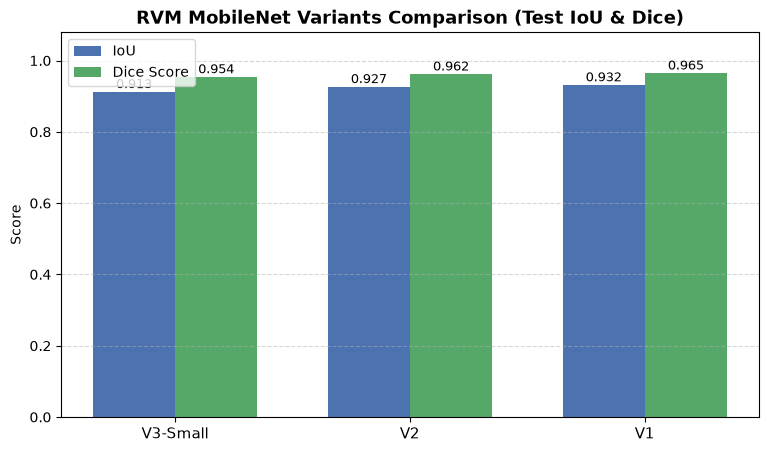

In [6]:
# กราฟเปรียบเทียบ IoU และ Dice
if not comparison_df.empty:
    short_labels = comparison_df["Short"]
    x = np.arange(len(comparison_df))
    w = 0.35

    plt.figure(figsize=(9, 5))
    plt.bar(x - w/2, comparison_df["IoU"], w, label="IoU", color="#4C72B0")
    plt.bar(x + w/2, comparison_df["Dice"], w, label="Dice Score", color="#55A868")

    for i in range(len(x)):
        plt.text(x[i] - w/2, comparison_df["IoU"].iloc[i] + 0.01, f"{comparison_df['IoU'].iloc[i]:.3f}", ha="center", fontsize=9)
        plt.text(x[i] + w/2, comparison_df["Dice"].iloc[i] + 0.01, f"{comparison_df['Dice'].iloc[i]:.3f}", ha="center", fontsize=9)

    plt.xticks(x, short_labels, fontsize=11)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title("RVM MobileNet Variants Comparison (Test IoU & Dice)", fontsize=13, fontweight="bold")
    plt.legend()
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.savefig(FIGURE_DIR / "backbone_comparison_iou_dice.png", dpi=200, bbox_inches="tight")
    plt.show()

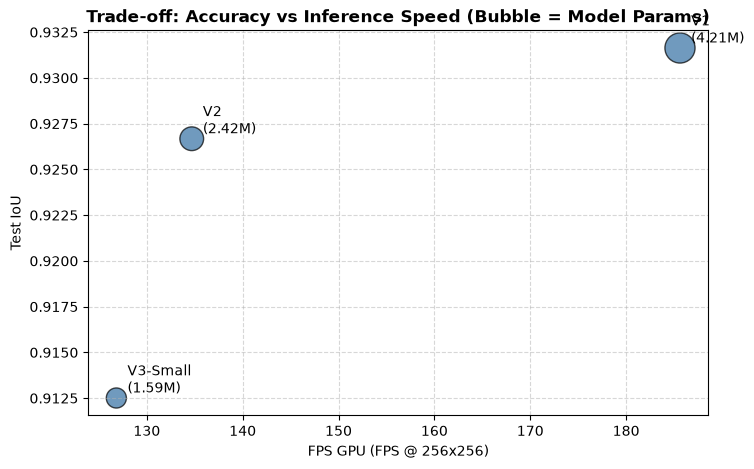

In [7]:
# กราฟ Accuracy (IoU) เทียบกับ Speed (FPS)
if not comparison_df.empty:
    plt.figure(figsize=(8, 5))
    target_fps_col = "FPS GPU" if device.type == "cuda" else "FPS CPU"

    plt.scatter(
        comparison_df[target_fps_col], comparison_df["IoU"],
        s=comparison_df["Params (M)"] * 100 + 50,
        c="#3470a3", alpha=0.7, edgecolors="black"
    )

    for i, row in comparison_df.iterrows():
        plt.annotate(
            f"{row['Short']}\n({row['Params (M)']:.2f}M)",
            (row[target_fps_col], row["IoU"]),
            textcoords="offset points", xytext=(8, 4), fontsize=10
        )

    plt.xlabel(f"{target_fps_col} (FPS @ 256x256)")
    plt.ylabel("Test IoU")
    plt.title("Trade-off: Accuracy vs Inference Speed (Bubble = Model Params)", fontsize=12, fontweight="bold")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.savefig(FIGURE_DIR / "backbone_accuracy_vs_speed.png", dpi=200, bbox_inches="tight")
    plt.show()

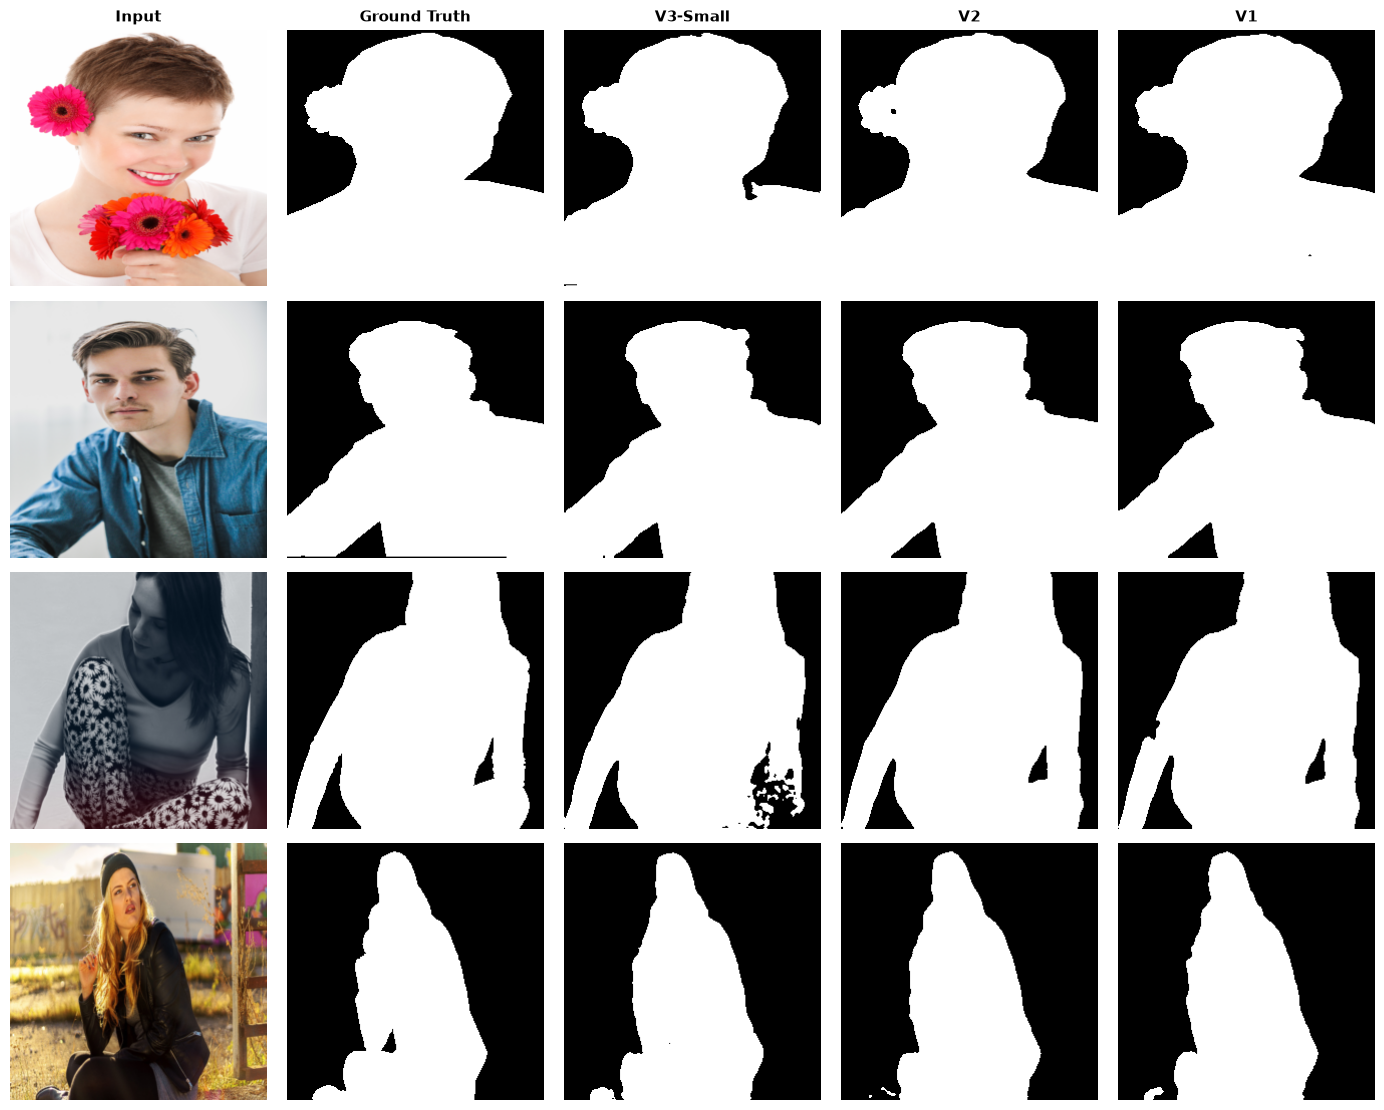

In [8]:
# แสดงตัวอย่างผลลัพธ์ภาพ (Qualitative Comparison)
N_SAMPLES = 4
images, masks, ids = next(iter(test_loader))
images = images[:N_SAMPLES].to(device)
masks = masks[:N_SAMPLES]

preds = {}
with torch.inference_mode():
    for name, model in loaded_models.items():
        logits, *_ = model(images, segmentation_pass=True)
        preds[name] = (torch.sigmoid(logits) >= 0.5).float().cpu()

cols = 2 + len(loaded_models)
fig, axes = plt.subplots(N_SAMPLES, cols, figsize=(2.8 * cols, 2.8 * N_SAMPLES))
axes = np.atleast_2d(axes)

titles = ["Input", "Ground Truth"] + [cfg["short"] for cfg in MODELS_CONFIG if cfg["name"] in loaded_models]

for i in range(N_SAMPLES):
    axes[i, 0].imshow(images[i].cpu().permute(1, 2, 0))
    axes[i, 1].imshow(masks[i, 0], cmap="gray")
    for j, name in enumerate(loaded_models):
        axes[i, 2 + j].imshow(preds[name][i, 0], cmap="gray")

for j, t in enumerate(titles):
    axes[0, j].set_title(t, fontsize=11, fontweight="bold")
for ax in axes.ravel():
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURE_DIR / "backbone_qualitative_all.png", dpi=200, bbox_inches="tight")
plt.show()